In [1]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from bs4 import BeautifulSoup
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from googletrans import Translator
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
import re
import time
import os  
import kagglehub

chromedriver_path = "/opt/homebrew/bin/chromedriver"
service = Service(chromedriver_path)
options = Options()

# options.add_argument("--headless")  # Uncomment untuk mode headless
options.add_argument("--disable-blink-features=AutomationControlled")
options.add_argument("--disable-extensions")
options.add_argument("--profile-directory=Default")
options.add_argument("--disable-infobars")
options.add_argument("--no-sandbox")
options.add_argument("--disable-dev-shm-usage")
options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36")

driver = None  
analyzer = SentimentIntensityAnalyzer()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SCRAPPING

In [2]:

def save_html(driver, filename="page_structure.html"):
    """
    Menyimpan struktur HTML dari halaman saat ini.
    """
    soup = BeautifulSoup(driver.page_source, "html.parser")
    with open(filename, "w", encoding="utf-8") as file:
        file.write(soup.prettify())
    print(f"Struktur HTML disimpan ke {filename}")

def get_driver():
    """
    Menginisialisasi driver hanya saat diperlukan.
    """
    global driver
    if not driver:
        driver = webdriver.Chrome(service=service, options=options)
    return driver

def scrape_all_video_links(url):
    """
    Mengambil semua link video dari halaman TikTok pengguna dengan scrolling.
    """
    if not url:
        print("URL tidak valid. Silakan masukkan URL yang benar.")
        return []
    
    driver = get_driver()
    driver.get(url)
    print("Silakan selesaikan CAPTCHA jika muncul.")
    input("Tekan ENTER setelah Anda menyelesaikan CAPTCHA...")
    
    SCROLL_PAUSE_TIME = 3
    last_height = driver.execute_script("return document.body.scrollHeight")
    
    while True:
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        time.sleep(SCROLL_PAUSE_TIME)
        new_height = driver.execute_script("return document.body.scrollHeight")
        if new_height == last_height:
            break
        last_height = new_height
    
    soup = BeautifulSoup(driver.page_source, "html.parser")
    video_links = [link["href"] for link in soup.find_all("a", href=True) if "/video/" in link["href"]]
    video_links = list(set(video_links))
    print(f"Jumlah video ditemukan: {len(video_links)}")
    
    return video_links

def scrape_tiktok_comments(url):
    """
    Mengambil semua komentar dari satu video TikTok dengan waktu tunggu.
    """
    if not url:
        print("URL tidak valid. Silakan masukkan URL yang benar.")
        return []

    try:
        driver = get_driver()
        driver.get(url)
        time.sleep(5)
        soup = BeautifulSoup(driver.page_source, "html.parser")
        comment_elements = soup.find_all("span", class_="TUXText TUXText--tiktok-sans TUXText--weight-normal")
        comments = [element.get_text() for element in comment_elements]
        print(f"Jumlah komentar ditemukan di {url}: {len(comments)}")
        return comments
    except Exception as e:
        print(f"Terjadi error saat mengambil komentar: {e}")
        input("Tekan ENTER untuk mencoba lagi...")
        return scrape_tiktok_comments(url)
    
def load_video_links_from_csv(csv_file):
    """
    Memuat link video dari file CSV jika ada.
    """
    if os.path.exists(csv_file):
        df = pd.read_csv(csv_file)
        return df["VideoLink"].tolist()
    return []

def save_video_links_to_csv(video_links, csv_file):
    """
    Menyimpan link video ke file CSV.
    """
    df = pd.DataFrame({"VideoLink": video_links})
    df.to_csv(csv_file, index=False)
    print(f"Link video disimpan ke '{csv_file}'.")

def load_processed_comments(csv_file):
    """
    Memuat komentar yang sudah diproses dari file CSV jika ada.
    """
    if os.path.exists(csv_file):
        df = pd.read_csv(csv_file)
        return df
    return pd.DataFrame(columns=["VideoLink", "Comment"])

def save_comments_to_csv(df, csv_file):
    """
    Menyimpan komentar yang sudah diproses ke file CSV.
    """
    df.to_csv(csv_file, index=False)
    print(f"Komentar disimpan ke '{csv_file}'.")

SENTIMENT

In [3]:
def load_words(file_path):
    """
    Memuat daftar kata bahasa Inggris dari file teks menjadi set.
    """
    with open(file_path, "r", encoding="utf-8") as file:
        return set(word.strip().lower() for word in file)

def translate_google(comments):
    """
    Menerjemahkan komentar dari bahasa indonesia ke bahasa inggris menggunakan Google Translate.
    """
    translator = Translator()
    translated_comments = []

    for comment in comments:
        if not comment.strip():  # Jika string kosong atau hanya spasi
            translated_comments.append("none")
            continue
        try:
            if len(comment.split()) > 5:
                translated = translator.translate(comment, src='id', dest='en').text
                print(translated)
                translated_comments.append(translated)
        except Exception as e:
            print(f"Translation failed for comment '{comment}': {e}")
            translated_comments.append("none")

    return translated_comments
    
    # driver = get_driver()
    # driver.get("https://translate.google.com")

    # translated_comments = []

    # # Pilih bahasa sumber sebagai Bahasa Indonesia
    # driver.find_element(By.XPATH, '//button[@aria-label="More source languages"]').click()
    # time.sleep(1)
    # driver.find_element(By.XPATH, '//div[contains(text(), "Indonesian")]').click()
    # time.sleep(1)

    # # Masukkan komentar satu per satu
    # for comment in comments:
    #     input_box = driver.find_element(By.XPATH, '//textarea[@aria-label="Source text"]')
    #     input_box.clear()  # Hapus teks sebelumnya
    #     input_box.send_keys(comment)
    #     time.sleep(2)

    #     # Ambil hasil terjemahan
    #     output_box = driver.find_element(By.XPATH, '//div[@class="lRu31"]')
    #     translated_text = output_box.text
    #     translated_comments.append(translated_text)

    # return translated_comments

def preprocessing(comments, stop_words, english_words, indo_words):
    """
    Membersihkan komentar, termasuk menghapus URL, angka, emoji, karakter khusus,
    spasi ganda, melakukan normalisasi, stopword removal, stemming, dan tokenizing.
    """
    tokenized_comments = []
    normalized_comments = []
    
    # 1. Translate to english
    comments = translate_google(comments)

    for comment in comments:
        if not comment or comment.strip().lower() == "none":  # Abaikan komentar kosong atau 'None'
            continue
        
        # 2. Cleaning Data
        comment = re.sub(r"http\S+|www\S+|https\S+|\d+|[^a-zA-Z\s]", " ", comment)  # Hapus URL
        comment = re.sub(r"\s+", " ", comment).strip()  # Hapus spasi ganda
        
        # 3. Case Folding
        comment = comment.lower()

        # 4. Tokenizing
        tokens = comment.split()

        # 5. Stopword Removal (english)
        tokens = [word for word in tokens if word not in stop_words]

        # 6. Stemming (english & indonesia)
        stemmed_tokens = [word for word in tokens if word in english_words and word not in indo_words]
        
        if len(stemmed_tokens) > 4:
            # Gabungkan kembali hasil stemming
            normalized_comment = " ".join(stemmed_tokens)
            print(normalized_comment)

            # Simpan hasil tokenisasi dan normalisasi
            tokenized_comments.append(tokens)
            normalized_comments.append(normalized_comment)
            
    # Membuat DataFrame hasil preprocessing
    df = pd.DataFrame({
        "Normalized": normalized_comments,
    })
    
    # 7. Remove Duplicate Words in DataFrame
    df["Normalized"] = df["Normalized"].apply(remove_duplicate_words)

    return df

def vader(file):
    """
    Menganalisis sentimen komentar menggunakan VADER pada file CSV, memberikan skor per kata, 
    menambahkan total skor sentimen, dan status sentimen berdasarkan total skor.
    """
    print("Memuat data dari file...")
    df = pd.read_csv(file)

    if "Normalized" not in df.columns:
        print("Kolom 'Normalized' tidak ditemukan dalam file. Pastikan file sudah sesuai format.")
        return

    print("Melakukan analisis sentimen dengan VADER...")
    analyzer = SentimentIntensityAnalyzer()

    # Analisis sentimen untuk setiap komentar
    word_sentiments = []
    # overall_sentiments = []
    total_scores = []
    total_sentiments = []

    for comment in df["Normalized"].fillna(""):
        words = comment.split()
        word_scores = {}
        total_score = 0  # Inisialisasi total skor
        
        # Mendapatkan skor untuk setiap kata
        for word in words:
            scores = analyzer.polarity_scores(word)
            word_scores[word] = scores['compound']  # Simpan skor compound setiap kata
            total_score += scores['compound']  # Tambahkan skor compound ke total
        
        # Tentukan sentimen berdasarkan total skor
        if total_score > 0.05:
            total_sentiment = "Positive"
        elif total_score < -0.05:
            total_sentiment = "Negative"
        else:
            total_sentiment = "Neutral"

        # Hitung sentimen keseluruhan komentar
        # overall_score = analyzer.polarity_scores(comment)
        # if overall_score["compound"] > 0.05:
        #     overall_sentiment = "Positive"
        # elif overall_score["compound"] < -0.05:
        #     overall_sentiment = "Negative"
        # else:
        #     overall_sentiment = "Neutral"

        word_sentiments.append(word_scores)
        # overall_sentiments.append(overall_sentiment)
        total_scores.append(total_score)
        total_sentiments.append(total_sentiment)
    
    # Tambahkan hasil analisis ke DataFrame
    # df["Overall Sentiment"] = overall_sentiments
    df["Word Scores"] = word_sentiments
    df["Total Score"] = total_scores
    df["Total Sentiment"] = total_sentiments

    # Menyimpan kembali ke file CSV
    output_file = file.replace(".csv", "_sentiment.csv")
    df.to_csv(output_file, index=False)
    print(f"Hasil analisis sentimen, skor per kata, total skor, dan total sentimen disimpan ke '{output_file}'.")

def remove_duplicate_words(text):
    """
    Menghapus kata yang berulang dalam satu komentar.
    """
    words = text.split()
    seen = set()
    unique_words = [word for word in words if not (word in seen or seen.add(word))]
    return " ".join(unique_words)

def start(url, name_user):
    print("Memeriksa file CSV untuk link video...")
    video_links = load_video_links_from_csv(f"{name_user}_video.csv")
    
    if not video_links:
        print("Tidak ada link video di file CSV. Mengambil link dari halaman pengguna TikTok...")
        video_links = scrape_all_video_links(url)
        save_video_links_to_csv(video_links, f"{name_user}_video.csv")
    else:
        print(f"Memuat {len(video_links)} link video dari file CSV.")
    
    processed_df = load_processed_comments(f"{name_user}_comment.csv")
    processed_video_links = processed_df["VideoLink"].unique()
    
    for video_link in video_links:
        if video_link in processed_video_links:
            print(f"Komentar dari video {video_link} sudah diambil sebelumnya, melewati...")
            continue
        
        print(f"Mengambil komentar dari video: {video_link}")
        comments = scrape_tiktok_comments(video_link)

        if comments:
            temp_df = pd.DataFrame({
                "VideoLink": [video_link] * len(comments),
                "Comment": comments
            })
            processed_df = pd.concat([processed_df, temp_df], ignore_index=True)
            save_comments_to_csv(processed_df, f"{name_user}_comment.csv")
    
    print("Proses selesai. Komentar disimpan.")
    
def sentiment(file_comment):
    """
    Memproses komentar dari file CSV, menerjemahkannya ke bahasa Inggris,
    dan membersihkan hasilnya berdasarkan kriteria.
    """
    # Langkah 1: Memuat data
    print("Memuat komentar...")
    df = load_processed_comments(file_comment)
    df = df.dropna(subset=["Comment"]).reset_index(drop=True)

    # Langkah 2: Memuat resources
    print("Memuat resources...")
    indo_words = load_words("bahasa indonesia/root_words.txt")
    english_words = load_words("bahasa inggris/english_words2.txt")
    english_stop_words = load_words("bahasa inggris/english_stopwords.txt")

    # Langkah 3: Preprocessing
    print("Memproses komentar...")
    fix_comment = preprocessing(df["Comment"].tolist(), english_stop_words, english_words, indo_words)

    # Langkah 4: Simpan hasil
    print("Menyimpan hasil...")
    output_file = file_comment.replace(".csv", "_cleaned.csv")
    fix_comment.to_csv(output_file, index=False)
    print(f"Hasil disimpan ke {output_file}")

DE GADJAH

In [4]:
start("https://www.tiktok.com/@degadjah", "gadjah")

Memeriksa file CSV untuk link video...
Memuat 1359 link video dari file CSV.
Mengambil komentar dari video: https://www.tiktok.com/@degadjah/video/7362059286249311494
Jumlah komentar ditemukan di https://www.tiktok.com/@degadjah/video/7362059286249311494: 0
Mengambil komentar dari video: https://www.tiktok.com/@degadjah/video/7225566124732075291
Jumlah komentar ditemukan di https://www.tiktok.com/@degadjah/video/7225566124732075291: 0
Komentar dari video https://www.tiktok.com/@degadjah/video/7430026681546542343 sudah diambil sebelumnya, melewati...
Komentar dari video https://www.tiktok.com/@degadjah/video/7434670714654903607 sudah diambil sebelumnya, melewati...
Komentar dari video https://www.tiktok.com/@degadjah/video/7024856238353616154 sudah diambil sebelumnya, melewati...
Komentar dari video https://www.tiktok.com/@degadjah/video/7071030545198714139 sudah diambil sebelumnya, melewati...
Komentar dari video https://www.tiktok.com/@degadjah/video/7057034258145217819 sudah diambil 

KeyboardInterrupt: 

In [5]:
sentiment("gadjah_comment.csv")

Memuat komentar...
Memuat resources...
Memproses komentar...
Logically, it's good to choose in the same direction as the elected president.Let the program be in line.Spirit and win sir.
This is the Keep Calm Stay Humble Millennial Smart Gas Mulia Pass one path🤙🔥🔥
See you November 10 in Singaraja Mr. De .... 🥰 MDH2an my husband Maan the opportunity to take a photo of Sareng Pak De.
when the younger generation became a leader.
no main drama ne pak de
great pak de slm 1 commando
Mih, hopefully when we are in a kreneng, we don't enter the clip to the tiktok,
Support Koster Giri, let's turn on two periods 🤟
JEG Loler Sajan Ne Bakar Dije Ne Pakde🥰🥰🥰
Koster Giri shows that experience is important 💖
Remember 27 date 27 November 2024
Come to busy to the TPS voted No.1 Mulia-Pas #Degadjahgubber GovernorBali2024
#Degadjahnyameng
Two periods for Koster Giri, all lights up wi 💪
Pak de Gadjah main ne governor of Bali 🙏🙏🙏
If the newcomers can vote, I will definitely vote de Gadjah, so that the airpor

In [6]:
vader("gadjah_comment_cleaned.csv")

Memuat data dari file...
Melakukan analisis sentimen dengan VADER...
Hasil analisis sentimen, skor per kata, total skor, dan total sentimen disimpan ke 'gadjah_comment_cleaned_sentiment.csv'.


In [13]:
data_gadjah = pd.read_csv("gadjah_comment_cleaned_sentiment.csv")
data_gadjah.groupby("Total Sentiment")["Total Sentiment"].value_counts()

Total Sentiment
Negative      9
Neutral      31
Positive    236
Name: count, dtype: int64

In [10]:
data_gadjah.to_excel("gadjah_comment_cleaned_sentiment.xlsx", index=False)
print(len(data_gadjah))

276


KOSTER

In [104]:
start("https://www.tiktok.com/@koster.menjawab", "koster_menjawab")

Memeriksa file CSV untuk link video...
Tidak ada link video di file CSV. Mengambil link dari halaman pengguna TikTok...
Silakan selesaikan CAPTCHA jika muncul.
Jumlah video ditemukan: 35
Link video disimpan ke 'koster_menjawab_video.csv'.
Mengambil komentar dari video: https://www.tiktok.com/@koster.menjawab/video/7430756072249412881
Jumlah komentar ditemukan di https://www.tiktok.com/@koster.menjawab/video/7430756072249412881: 60
Komentar disimpan ke 'koster_menjawab_comment.csv'.
Mengambil komentar dari video: https://www.tiktok.com/@koster.menjawab/video/7434282980656286977
Jumlah komentar ditemukan di https://www.tiktok.com/@koster.menjawab/video/7434282980656286977: 60
Komentar disimpan ke 'koster_menjawab_comment.csv'.
Mengambil komentar dari video: https://www.tiktok.com/@koster.menjawab/video/7433738612400803088
Jumlah komentar ditemukan di https://www.tiktok.com/@koster.menjawab/video/7433738612400803088: 60
Komentar disimpan ke 'koster_menjawab_comment.csv'.
Mengambil komenta

In [19]:
koster1 = pd.read_csv("koster_comment.csv")
koster2 = pd.read_csv("koster_menjawab_comment.csv")
koster_gabung = pd.concat([koster1, koster2]).reset_index(drop=True)
koster_gabung.to_csv("koster_final_comment.csv", index=False)

In [20]:
sentiment("koster_final_comment.csv")

Memuat komentar...
Memuat resources...
Memproses komentar...
omon omon gen 😂😂😂 One Comando is more confident 😂
Buleleng Caman Kal Maju Yan?Pocol Gati Wayan Ling Buleleng
The discourse of the gene genes shifted the votes of the ambisui so Mr. Tomn
we don't need a toll road sir ,,
Great sir yan.Let's succeed in Bali with a noble passs
Liunan Pak Yan's theory ... jani, the era of the young people who advanced ... old resting
Tumben sing meudeng jak mesaput barracks ???
Yes, if it is easy from the center, different paths can be more difficult.
02 wins, win, win, Pang ad deposit to the party ....
And only you are the money on the money 😂
Pak yan .. education invites health ... Baline community .. Engken Program Ne ??
Government will be better if linear from the center to the region ...
Greetings of common sense ...
One Commando 👍
Sorry Mr. Yan, the Sube Pole Sing believes in inviting Mr. Yan.
Degugune Koster Omon Omon Gen Sing Ade Ape De
There have been a lot of one comando lane, many stall

In [21]:
vader("koster_final_comment_cleaned.csv")

Memuat data dari file...
Melakukan analisis sentimen dengan VADER...
Hasil analisis sentimen, skor per kata, total skor, dan total sentimen disimpan ke 'koster_final_comment_cleaned_sentiment.csv'.


In [30]:
data_koster = pd.read_csv("koster_final_comment_cleaned_sentiment.csv")
data_koster.groupby("Total Sentiment")["Total Sentiment"].value_counts()

Total Sentiment
Negative     28
Neutral      70
Positive    249
Name: count, dtype: int64

In [31]:
data_koster.to_excel("koster_final_comment_cleaned_sentiment.xlsx", index=False)
print(len(data_koster))

347


COMBINE

Hasil 1

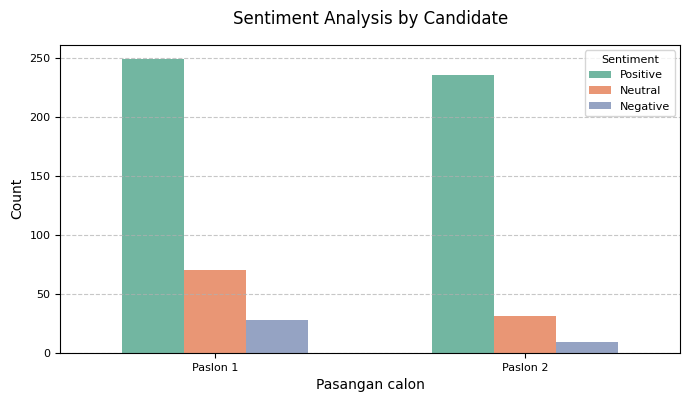

In [36]:
data = pd.DataFrame({
    "Sentiment": pd.concat([data_koster["Total Sentiment"],data_gadjah["Total Sentiment"]], ignore_index=True),
    "Paslon": ["Paslon 1"]*347 + ["Paslon 2"]*276 
})

group = data.groupby("Paslon")["Sentiment"].value_counts().reset_index()

plt.figure(figsize=(8, 4)) 
sns.barplot(x="Paslon", y="count", hue="Sentiment", data=group, palette="Set2", width=0.6) 
plt.title("Sentiment Analysis by Candidate", pad=15, fontsize=12)
plt.xlabel("Pasangan calon", fontsize=10)
plt.ylabel("Count", fontsize=10)
plt.legend(title="Sentiment", title_fontsize=8, fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8) 
plt.grid(axis='y', linestyle='--', alpha=0.7)


Hasil 2

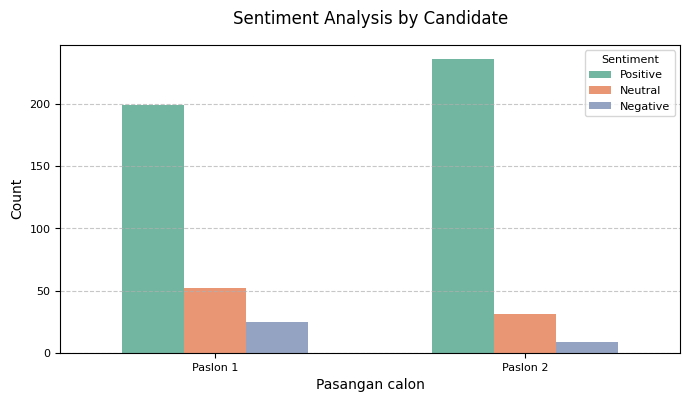

In [37]:
data = pd.DataFrame({
    "Sentiment": pd.concat([data_koster.head(276)["Total Sentiment"],data_gadjah["Total Sentiment"]], ignore_index=True),
    "Paslon": ["Paslon 1"]*276 + ["Paslon 2"]*276 
})

group = data.groupby("Paslon")["Sentiment"].value_counts().reset_index()

plt.figure(figsize=(8, 4)) 
sns.barplot(x="Paslon", y="count", hue="Sentiment", data=group, palette="Set2", width=0.6) 
plt.title("Sentiment Analysis by Candidate", pad=15, fontsize=12)
plt.xlabel("Pasangan calon", fontsize=10)
plt.ylabel("Count", fontsize=10)
plt.legend(title="Sentiment", title_fontsize=8, fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8) 
plt.grid(axis='y', linestyle='--', alpha=0.7)